In [ ]:
from google.colab import files
uploaded = files.upload()

Found 10 user files to process:
 - User10_Calib_3MouseMovement_MCQ_Segment.csv
 - User1_Calib_3MouseMovement_MCQ_Segment.csv
 - User2_Calib_3MouseMovement_MCQ_Segment.csv
 - User3_Calib_3MouseMovement_MCQ_Segment.csv
 - User4_Calib_3MouseMovement_MCQ_Segment.csv
 - User5_Calib_3MouseMovement_MCQ_Segment.csv
 - User6_Calib_3MouseMovement_MCQ_Segment.csv
 - User7_Calib_3MouseMovement_MCQ_Segment.csv
 - User8_Calib_3MouseMovement_MCQ_Segment.csv
 - User9_Calib_3MouseMovement_MCQ_Segment.csv

All files loaded successfully. Consolidated Shape: (2002, 69)
Target Labels: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]

Generating kinematic verification plots...


/tmp/ipykernel_815/3107437456.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="label", y="avg_tv", ax=axes[0], palette="Set2")


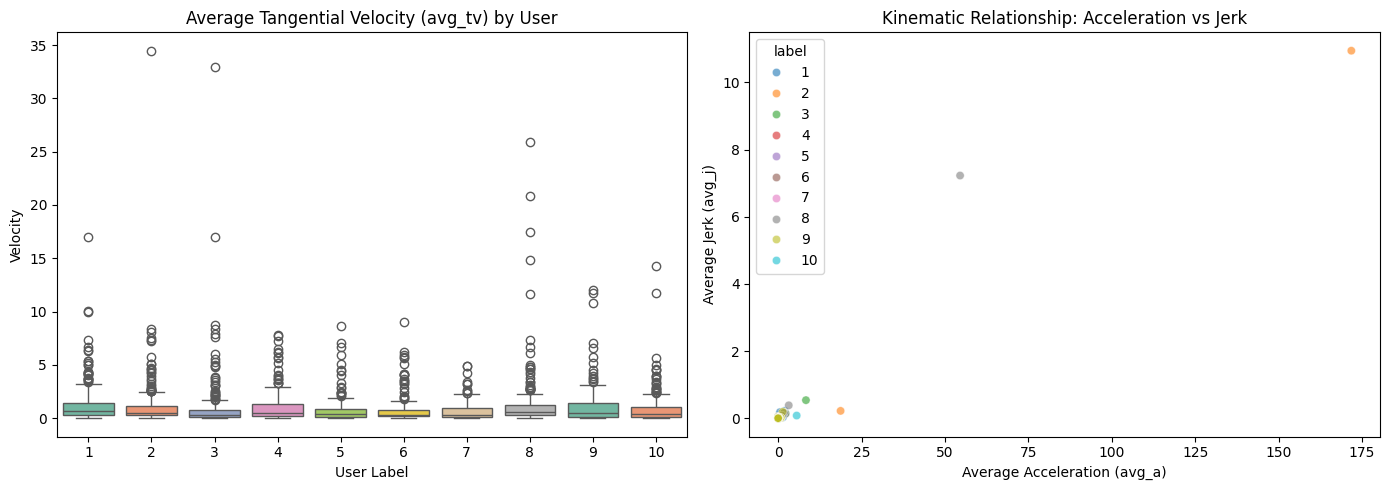


Extracting Feature Sets 0 to 3...

Evaluating baseline SVM classifier across feature sets...

=== EVALUATION SUMMARY TABLE ===
                       Feature Set  Features Count  Accuracy  Precision  Recall (Sensitivity)  F1-Score
          Feature Set 0 (Baseline)              68    0.5589     0.5537                0.5589    0.5453
          Feature Set 1 (L1-based)              48    0.5529     0.5439                0.5529    0.5373
Feature Set 2 (Correlation-pruned)              24    0.5030     0.4942                0.5030    0.4826
Feature Set 3 (Mutual Information)              15    0.4491     0.4769                0.4491    0.4442

Saved 'eda_kinematics_verification.png' and 'benchmark_metrics_summary.csv' to Colab Files.


In [1]:
import glob
import os
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# --- 1. DATA LOADER & FILE CONCATENATION ---
# Match the exact file naming pattern from Colab
file_pattern = "*Calib_3MouseMovement_MCQ_Segment.csv"
file_list = sorted(glob.glob(file_pattern))

if not file_list:
  # Fallback check in case files were uploaded to sample_data
  file_list = sorted(glob.glob("sample_data/" + file_pattern))

if not file_list:
  raise FileNotFoundError(
      f"No files matching '{file_pattern}' were found in Colab directory. Please"
      " check your sidebar."
  )

print(f"Found {len(file_list)} user files to process:")
for f in file_list:
  print(f" - {f}")

dataframes = []
for file_path in file_list:
  temp_df = pd.read_csv(file_path)
  temp_df.columns = [c.strip() for c in temp_df.columns]

  # Extract user ID (e.g., User1 -> 1, User2 -> 2)
  match = re.search(r"User(\d+)", os.path.basename(file_path), re.IGNORECASE)
  user_num = int(match.group(1)) if match else os.path.basename(file_path)

  # Ensure label column matches user ID
  if "label" not in temp_df.columns or temp_df["label"].isnull().all():
    temp_df["label"] = user_num
  else:
    # Overwrite with user ID to guarantee separation across files
    temp_df["label"] = user_num

  dataframes.append(temp_df)

df = pd.concat(dataframes, ignore_index=True)

# Clean numerical values
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.fillna(df.median(numeric_only=True), inplace=True)

print(f"\nAll files loaded successfully. Consolidated Shape: {df.shape}")
print(f"Target Labels: {sorted(df['label'].unique())}")

# --- 2. EDA & DEMONSTRATION VISUALIZATIONS ---
print("\nGenerating kinematic verification plots...")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Velocity distribution across users
if "avg_tv" in df.columns:
  sns.boxplot(data=df, x="label", y="avg_tv", ax=axes[0], palette="Set2")
  axes[0].set_title("Average Tangential Velocity (avg_tv) by User")
  axes[0].set_xlabel("User Label")
  axes[0].set_ylabel("Velocity")

# Plot 2: Acceleration vs Jerk distribution
if "avg_a" in df.columns and "avg_j" in df.columns:
  sns.scatterplot(
      data=df,
      x="avg_a",
      y="avg_j",
      hue="label",
      alpha=0.6,
      ax=axes[1],
      palette="tab10",
  )
  axes[1].set_title("Kinematic Relationship: Acceleration vs Jerk")
  axes[1].set_xlabel("Average Acceleration (avg_a)")
  axes[1].set_ylabel("Average Jerk (avg_j)")

plt.tight_layout()
plt.savefig("eda_kinematics_verification.png", dpi=300)
plt.show()

# --- 3. FEATURE SELECTION PIPELINE (SETS 0 TO 3) ---
print("\nExtracting Feature Sets 0 to 3...")
drop_cols = ["Seg Id", "label"]
y = df["label"]
X = df.drop(columns=[c for c in drop_cols if c in df.columns], errors="ignore")

# Remove any remaining non-numeric columns
X = X.select_dtypes(include=[np.number])

# Standardize inputs
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# Feature Set 0: Baseline (All available features)
X_set0 = X_scaled

# Feature Set 1: L1-based selection
l1_model = LogisticRegression(
    penalty="l1", solver="liblinear", C=0.2, random_state=42
)
l1_model.fit(X_scaled, y)
l1_mask = np.abs(l1_model.coef_).sum(axis=0) > 1e-4
X_set1 = X_scaled.loc[:, l1_mask]

# Feature Set 2: Correlation Pruning (threshold r > 0.85)
corr_matrix = X.corr().abs()
upper_tri = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)
drop_corr = [
    col for col in upper_tri.columns if any(upper_tri[col] > 0.85)
]  # cite: 4
X_set2 = X_scaled.drop(columns=drop_corr)

# Feature Set 3: Mutual Information / SelectKBest
k_features = min(15, X_scaled.shape[1])
mi_selector = SelectKBest(score_func=mutual_info_classif, k=k_features)
mi_selector.fit(X_scaled, y)
X_set3 = X_scaled.loc[:, mi_selector.get_support()]

feature_dict = {
    "Feature Set 0 (Baseline)": X_set0,  # cite: 3
    "Feature Set 1 (L1-based)": X_set1,  # cite: 4
    "Feature Set 2 (Correlation-pruned)": X_set2,  # cite: 4
    "Feature Set 3 (Mutual Information)": X_set3,  # cite: 4
}

# --- 4. BENCHMARK DEMONSTRATION & EVALUATION ---
print("\nEvaluating baseline SVM classifier across feature sets...")
records = []
for name, X_data in feature_dict.items():
  X_train, X_test, y_train, y_test = train_test_split(
      X_data, y, test_size=0.25, stratify=y, random_state=42
  )

  clf = SVC(kernel="rbf", C=1.0, random_state=42)  # cite: 5
  clf.fit(X_train, y_train)
  preds = clf.predict(X_test)

  records.append({
      "Feature Set": name,
      "Features Count": X_data.shape[1],
      "Accuracy": round(accuracy_score(y_test, preds), 4),  # cite: 5
      "Precision": round(
          precision_score(y_test, preds, average="weighted", zero_division=0), 4
      ),  # cite: 5
      "Recall (Sensitivity)": round(
          recall_score(y_test, preds, average="weighted", zero_division=0), 4
      ),  # cite: 5
      "F1-Score": round(
          f1_score(y_test, preds, average="weighted", zero_division=0), 4
      ),
  })

results_df = pd.DataFrame(records)
print("\n=== EVALUATION SUMMARY TABLE ===")
print(results_df.to_string(index=False))

# Export artifacts to files panel
results_df.to_csv("benchmark_metrics_summary.csv", index=False)
print(
    "\nSaved 'eda_kinematics_verification.png' and"
    " 'benchmark_metrics_summary.csv' to Colab Files."
)

              TOP 15 BEST MOUSE DYNAMICS FEATURES (CONSENSUS)           
   Feature  Mutual_Info_Score  RF_Importance  L1_Weight  Composite_Score
     max_t           0.833551       0.051735  14.088076         2.666667
        t1           0.828352       0.058448   4.790509         3.000000
        t2           0.827320       0.049243   3.381301         5.333333
        t0           0.824013       0.055402   2.961072         5.666667
     min_t           0.819241       0.048282   1.264258         8.333333
     max_y           0.482455       0.036527   3.178641         8.666667
        y0           0.473337       0.027392   2.129341        11.333333
        y2           0.513951       0.026177   0.799266        13.000000
        x2           0.313591       0.018309   0.855073        17.333333
        x0           0.297775       0.019014   0.982806        17.666667
     min_a           0.141290       0.007812   5.243407        18.666667
     avg_t           0.785869       0.059273   0.00

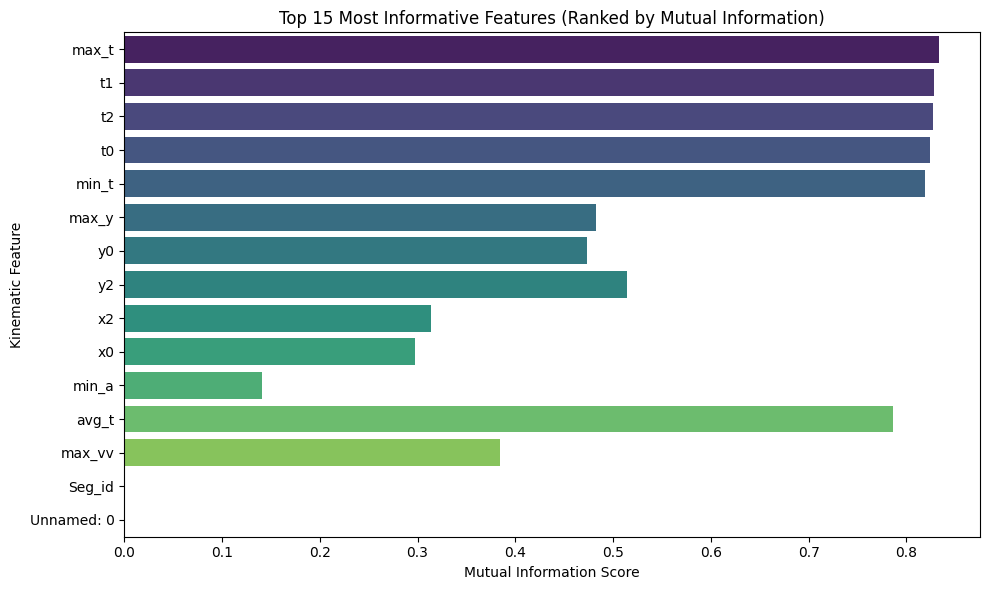


Files successfully created:
 - 'top_15_best_features.csv'
 - 'top_features_importance.png'


In [3]:
import glob
import os
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# --- 1. LOAD AND AGGREGATE MULTI-USER DATA ---
file_pattern = "*Calib_3MouseMovement_MCQ_Segment.csv"
file_list = sorted(glob.glob(file_pattern))

if not file_list:
  file_list = sorted(glob.glob("sample_data/" + file_pattern))

if not file_list:
  raise FileNotFoundError(
      f"No files matching '{file_pattern}' found. Please upload them in Colab."
  )

dataframes = []
for file_path in file_list:
  temp_df = pd.read_csv(file_path)
  temp_df.columns = [c.strip() for c in temp_df.columns]

  match = re.search(r"User(\d+)", os.path.basename(file_path), re.IGNORECASE)
  user_num = int(match.group(1)) if match else os.path.basename(file_path)
  temp_df["label"] = user_num
  dataframes.append(temp_df)

df = pd.concat(dataframes, ignore_index=True)
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.fillna(df.median(numeric_only=True), inplace=True)

# Separate predictors from identifiers
drop_cols = ["Seg Id", "label"]
y = df["label"]
X = df.drop(columns=[c for c in drop_cols if c in df.columns], errors="ignore")
X = X.select_dtypes(include=[np.number])

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# --- 2. RANKING METHOD 1: MUTUAL INFORMATION (NON-LINEAR) ---
mi_scores = mutual_info_classif(X_scaled, y, random_state=42)
mi_ranking = pd.DataFrame({
    "Feature": X.columns,
    "Mutual_Info_Score": mi_scores,
}).sort_values(by="Mutual_Info_Score", ascending=False)

# --- 3. RANKING METHOD 2: RANDOM FOREST GINI IMPORTANCE ---
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_scaled, y)
rf_ranking = pd.DataFrame({
    "Feature": X.columns,
    "RF_Importance": rf.feature_importances_,
}).sort_values(by="RF_Importance", ascending=False)

# --- 4. RANKING METHOD 3: L1-LOGISTIC REGRESSION SPARSITY ---
l1_model = LogisticRegression(
    penalty="l1", solver="liblinear", C=0.2, random_state=42
)
l1_model.fit(X_scaled, y)
l1_weights = np.abs(l1_model.coef_).sum(axis=0)
l1_ranking = pd.DataFrame({
    "Feature": X.columns,
    "L1_Weight": l1_weights,
}).sort_values(by="L1_Weight", ascending=False)

# --- 5. ENSEMBLE CONSENSUS RANKING ---
consensus_df = mi_ranking.merge(rf_ranking, on="Feature").merge(
    l1_ranking, on="Feature"
)
consensus_df["Rank_MI"] = consensus_df["Mutual_Info_Score"].rank(
    ascending=False
)
consensus_df["Rank_RF"] = consensus_df["RF_Importance"].rank(ascending=False)
consensus_df["Rank_L1"] = consensus_df["L1_Weight"].rank(ascending=False)

consensus_df["Composite_Score"] = (
    consensus_df["Rank_MI"] + consensus_df["Rank_RF"] + consensus_df["Rank_L1"]
) / 3
consensus_df = consensus_df.sort_values(by="Composite_Score")

top_15_features = consensus_df.head(15).reset_index(drop=True)

print("=" * 80)
print("              TOP 15 BEST MOUSE DYNAMICS FEATURES (CONSENSUS)           ")
print("=" * 80)
print(
    top_15_features[[
        "Feature",
        "Mutual_Info_Score",
        "RF_Importance",
        "L1_Weight",
        "Composite_Score",
    ]].to_string(index=False)
)

# Export ranked list to CSV
top_15_features.to_csv("top_15_best_features.csv", index=False)

# --- 6. PLOT TOP FEATURE IMPORTANCE ---
plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_15_features,
    x="Mutual_Info_Score",
    y="Feature",
    palette="viridis",
    hue="Feature",
    legend=False,
)
plt.title("Top 15 Most Informative Features (Ranked by Mutual Information)")
plt.xlabel("Mutual Information Score")
plt.ylabel("Kinematic Feature")
plt.tight_layout()
plt.savefig("top_features_importance.png", dpi=300)
plt.show()

print("\nFiles successfully created:")
print(" - 'top_15_best_features.csv'")
print(" - 'top_features_importance.png'")

In [ ]:
from google.colab import files

files.download('eda_kinematics_verification.png')
files.download('benchmark_metrics_summary.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>